<a href="https://colab.research.google.com/github/nistoriuliana23/ML-Seminar-NistorIuliana/blob/main/Tema_Laborator_3_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Temă LP3 — Preprocesarea datelor (Titanic)

**Timp de lucru: maximum 15 minute** · lucru individual

Aplicați tehnicile din LP3 pe un set de date nou: **Titanic** — informații despre pasagerii navei (vârstă, sex, preț bilet, port de îmbarcare, punte) și dacă au supraviețuit (`survived`).

| Sarcina | Tema | Timp |
| --- | --- | --- |
| 1 | Valori lipsă: diagnostic și eliminare pe bază de prag | ~3 min |
| 2 | Imputarea valorilor lipsă | ~3 min |
| 3 | Asimetrie și transformare logaritmică | ~3 min |
| 4 | Outlieri (regula IQR) | ~3 min |
| 5 | Encoding și scalare | ~3 min |

> 💡 Completați celulele marcate `# TODO`. Nu e nevoie de cod perfect — contează să înțelegeți ce face fiecare pas.

### Pregătire — rulați celula (nu necesită modificări)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

titanic = sns.load_dataset('titanic')
df = titanic[['survived', 'pclass', 'sex', 'age', 'fare', 'embarked', 'deck']].copy()
df.head()

,survived,pclass,sex,age,fare,embarked,deck
0,0,3,male,22.0,7.2500,S,NaN
1,1,1,female,38.0,71.2833,C,C
2,1,3,female,26.0,7.9250,S,NaN
3,1,1,female,35.0,53.1000,S,C
4,0,3,male,35.0,8.0500,S,NaN


## Sarcina 1 — Valori lipsă (~3 min)

**1.1** Calculați procentul de valori lipsă pentru fiecare coloană, sortat descrescător.

**1.2** Eliminați coloanele cu **mai mult de 50%** valori lipsă. Care coloană dispare?

In [7]:
# TODO 1.1 — procentul de valori lipsă pe coloană
(df.isna().mean() * 100).sort_values(ascending=False)

# TODO 1.2 — eliminați coloanele cu > 50% valori lipsă
df = df.loc[:, df.isna().mean() <= 0.5]
df.head()

,survived,pclass,sex,age,fare,embarked
0,0,3,male,22.0,7.2500,S
1,1,1,female,38.0,71.2833,C
2,1,3,female,26.0,7.9250,S
3,1,1,female,35.0,53.1000,S
4,0,3,male,35.0,8.0500,S


## Sarcina 2 — Imputarea valorilor lipsă (~3 min)

**2.1** Imputați `age` cu **mediana** și `embarked` cu **valoarea cea mai frecventă** (modul).

**2.2** Verificați că nu mai există valori lipsă și comparați deviația standard a lui `age` înainte și după imputare. *(salvați înainte de imputare: `age_inainte = df['age'].copy()`)*

In [15]:
# TODO 2.1 — imputare age (mediană) și embarked (mod)
age_inainte = df['age'].copy()
age_inainte = df['age'].copy()

df['age'] = df['age'].fillna(df['age'].median())
df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])

df.head()

# TODO 2.2 — verificare + comparație deviație standard

print("Deviația standard înainte:", age_inainte.std())
print("Deviația standard după:", df['age'].std())

print("Valori lipsă înainte:", age_inainte.isna().sum())
print("Valori lipsă după:", df['age'].isna().sum())
print("Valori lipsă embarked:", df['embarked'].isna().sum())

Deviația standard înainte: 13.019696550973194
Deviația standard după: 13.019696550973194
Valori lipsă înainte: 0
Valori lipsă după: 0
Valori lipsă embarked: 0


## Sarcina 3 — Asimetrie și transformare logaritmică (~3 min)

**3.1** Calculați skewness-ul variabilei `fare`.

**3.2** Creați coloana `log_fare = np.log1p(fare)` și calculați skewness-ul ei. A ajutat transformarea?

**3.3** Desenați cele două histograme una lângă alta.

Skewness fare: 4.787316519674893
Skewness log_fare: 0.3949280095189306
Da, transformarea a redus skewness-ul.


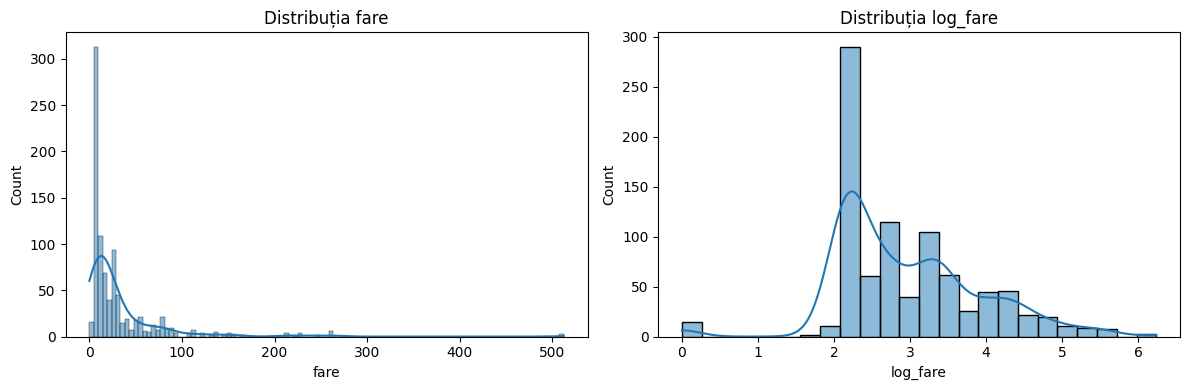

In [16]:
# TODO 3.1 — skewness fare
print("Skewness fare:", df['fare'].skew())

# TODO 3.2 — coloana log_fare + skewness

df['log_fare'] = np.log1p(df['fare'])

print("Skewness log_fare:", df['log_fare'].skew())


if abs(df['log_fare'].skew()) < abs(df['fare'].skew()):
    print("Da, transformarea a redus skewness-ul.")
else:
    print("Nu, transformarea nu a redus skewness-ul.")

# TODO 3.3 — două histograme

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
sns.histplot(df['fare'], kde=True)
plt.title('Distribuția fare')

plt.subplot(1, 2, 2)
sns.histplot(df['log_fare'], kde=True)
plt.title('Distribuția log_fare')

plt.tight_layout()
plt.show()

## Sarcina 4 — Outlieri cu regula IQR (~3 min)

**4.1** Calculați limitele `[Q1 − 1,5·IQR ; Q3 + 1,5·IQR]` pentru `fare` și numărați outlierii.

**4.2** Limitați (clip) valorile extreme într-o coloană nouă, `fare_capped`, și afișați maximul înainte și după.

In [17]:
# TODO 4.1 — limite IQR + număr de outlieri

Q1 = df['fare'].quantile(0.25)
Q3 = df['fare'].quantile(0.75)
IQR = Q3 - Q1

limita_inferioara = Q1 - 1.5 * IQR
limita_superioara = Q3 + 1.5 * IQR

print("Limita inferioară:", limita_inferioara)
print("Limita superioară:", limita_superioara)

outlieri = df[(df['fare'] < limita_inferioara) | (df['fare'] > limita_superioara)]
print("Număr de outlieri:", len(outlieri))

# TODO 4.2 — fare_capped (clip) + maxim înainte/după

df['fare_capped'] = df['fare'].clip(lower=limita_inferioara, upper=limita_superioara)

print("Maxim înainte:", df['fare'].max())
print("Maxim după:", df['fare_capped'].max())


Limita inferioară: -26.724
Limita superioară: 65.6344
Număr de outlieri: 116
Maxim înainte: 512.3292
Maxim după: 65.6344


## Sarcina 5 — Encoding și scalare (~3 min)

**5.1** Aplicați One-Hot Encoding pe `sex` și `embarked` (cu `drop_first=True`, `dtype=int`).

**5.2** Standardizați `age` și `fare_capped` cu `StandardScaler`. Verificați că media ≈ 0 și deviația standard ≈ 1.

In [26]:
# TODO 5.1 — One-Hot Encoding pentru sex și embarked

#df = pd.get_dummies(df, columns=['sex', 'embarked'], drop_first=True, dtype=int)

#df.head()

# Verificăm dacă coloanele originale mai există înainte de a aplica get_dummies
cols_to_encode = [col for col in ['sex', 'embarked'] if col in df.columns]
if cols_to_encode:
    df = pd.get_dummies(df, columns=cols_to_encode, drop_first=True, dtype=int)

df.head()

# TODO 5.2 — StandardScaler pentru age și fare_capped + verificare medie/std

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

df[['age_scaled', 'fare_capped_scaled']] = scaler.fit_transform(df[['age', 'fare_capped']])

print("Medii:")
print(df[['age_scaled', 'fare_capped_scaled']].mean())

print("Deviații standard:")
print(df[['age_scaled', 'fare_capped_scaled']].std(ddof=0))

Medii:
age_scaled            2.272780e-16
fare_capped_scaled    9.968332e-17
dtype: float64
Deviații standard:
age_scaled            1.0
fare_capped_scaled    1.0
dtype: float64


## Întrebare de reflecție (1–2 propoziții)

*De ce am imputat `age`, dar am eliminat `deck`?*

*Răspunsul tău:*

Am imputat age deoarece vârsta este o variabilă numerică importantă pentru analiză, iar valorile lipsă pot fi înlocuite cu mediana fără a modifica excesiv distribuția.

Am eliminat deck deoarece avea peste 50% valori lipsă. Imputarea unei proporții atât de mari ar fi putut introduce prea multe informații artificiale și rezultate mai puțin fiabile.